# Performance

Run all cells with the `silscore` environment; the included caches are sufficient.

Generated from [nb1_performance.py](nb1_performance.py).

In [1]:
"""Plot cached benchmark correlations and paired gains.

The panels show marginal confidence intervals and paired contrasts.
"""
from __future__ import annotations

import csv
import sys
from pathlib import Path

import matplotlib.pyplot as plt
from IPython.display import Image
from matplotlib.ticker import MaxNLocator

def _resolve_root() -> Path:
    file_name = globals().get("__file__")
    if file_name:
        return Path(file_name).resolve().parents[1]
    cwd = Path.cwd().resolve()
    if (cwd / "data" / "cache").is_dir():
        return cwd
    if cwd.name == "notebooks" and (cwd.parent / "data" / "cache").is_dir():
        return cwd.parent
    raise RuntimeError("cannot resolve Silscore root from __file__ or cwd")


ROOT = _resolve_root()
sys.path.insert(0, str(ROOT / "scripts" / "analysis"))
from prepare_oligoformer import load_metrics


# Font sizes in points.
FS_TICK = 8.0
FS_LABEL = 9.0
FS_TITLE = 8.0
FS_METHOD = 7.0

# Figure dimensions in inches.
FIG_W = 5.586        # Manuscript text width.
M_LEFT, M_RIGHT = 0.98, 0.06
M_TOP, M_BOTTOM = 0.46, 1.10
GAP_X, GAP_Y = 0.09, 0.035

BAR_WIDTH = 0.8
SILSCORE_KEY = "modello principale (V1)"
SILSCORE_LABEL = "Silscore"

# Required comparators; comp-21/21 is unavailable outside Huesken.
REQUIRED = ("fisica pura", "fisica + U1", SILSCORE_KEY)

ORDER = [
    ("Reynolds 2004", "Reynolds", "lightgray"),
    ("Ui-Tei 2004", "Ui-Tei", "darkgray"),
    ("i-Score riadattato", "i-Score", "lightgreen"),
    ("DSIR sparse-19", "sparse-19", "gold"),
    ("DSIR spectrum-19", "spectrum-19", "orange"),
    ("DSIR composite-19/19", "comp-19/19", "darkorange"),
    ("DSIR composite-21/21", "comp-21/21", "sienna"),
    ("OligoFormer", "OligoFormer", "tab:purple"),
    ("fisica pura", "Thermo-only", "lightsteelblue"),
    ("fisica + U1", "Thermo+U1", "cornflowerblue"),
    (SILSCORE_KEY, SILSCORE_LABEL, "royalblue"),
]
COLUMNS = [
    ("249 (dominio)", "In domain\nHuesken ($n=249$)"),
    ("mix", "Cross-dataset\nMixset ($n=472$)"),
    ("taka", "Cross-dataset\nKS ($n=702$)"),
    ("specie (bersagli nuovi)", "Unseen targets\nHuesken ($n=1453$)"),
]


def read_data():
    rows = []
    for name in ("potency_vs_dsir.csv", "potency_specie_per_figura.csv"):
        with open(ROOT / "data" / "cache" / name) as fh:
            rows += list(csv.DictReader(fh))
    pearson = {(r["modello"], r["test"]): r for r in rows if r["confronto"] == "pearson"}
    contrasts = {(r["modello"].split(" - ", 1)[1], r["test"]): r
              for r in rows if r["confronto"] == "contrasto"
              and r["modello"].startswith(SILSCORE_KEY)}
    missing = [f"{m} / {key}" for m in REQUIRED for key, _ in COLUMNS
                if (m, key) not in pearson
                or (m != SILSCORE_KEY and (m, key) not in contrasts)]
    if missing:
        raise ValueError(f"required rows missing from V1 CSVs: {missing}")
    data = load_metrics(ROOT / "data" / "cache" / "oligoformer.json")
    for row in data["comparisons"]:
        if row["model"] == "human":
            continue
        test = {"eval_huesken249": "249 (dominio)", "eval_mix472": "mix",
                "eval_taka702": "taka", "eval_human1453": "specie (bersagli nuovi)"}[row["dataset"]]
        pearson["OligoFormer", test] = dict(valore=row["oligoformer_r"],
            ic_basso=row["ci_low"], ic_alto=row["ci_high"])
        contrasts["OligoFormer", test] = dict(valore=row["delta_silscore_minus_oligoformer"],
            ic_basso=row["delta_ci_low"], ic_alto=row["delta_ci_high"])
    return pearson, contrasts


def panel_grid(fig, side, fig_h):
    """Place eight square axes in a 4-column, 2-row grid using figure coordinates."""
    y_top = (M_BOTTOM + side + GAP_Y) / fig_h
    y_bottom = M_BOTTOM / fig_h
    axes = ([], [])
    for c in range(4):
        x = (M_LEFT + c * (side + GAP_X)) / FIG_W
        axes[0].append(fig.add_axes([x, y_top, side / FIG_W, side / fig_h]))
        axes[1].append(fig.add_axes([x, y_bottom, side / FIG_W, side / fig_h]))
    return axes


def main() -> int:
    pearson, contrasts = read_data()

    side = (FIG_W - M_LEFT - M_RIGHT - 3 * GAP_X) / 4
    fig_h = M_TOP + 2 * side + GAP_Y + M_BOTTOM
    fig = plt.figure(figsize=(FIG_W, fig_h), dpi=300)
    (top_axes, bottom_axes) = panel_grid(fig, side, fig_h)

    for col, (key, title) in enumerate(COLUMNS):
        top_ax = top_axes[col]
        for i, (name, _, color) in enumerate(ORDER):
            r = pearson.get((name, key))
            if r is None:                  # comp-21/21 requires overhangs.
                top_ax.text(i, 0.02, "n/a", ha="center", va="bottom", fontsize=FS_METHOD,
                          rotation=90, color="0.4")
                continue
            v, lo, hi = float(r["valore"]), float(r["ic_basso"]), float(r["ic_alto"])
            top_ax.bar(i, v, width=BAR_WIDTH, color=color, edgecolor="k", linewidth=0.6, zorder=3)
            top_ax.errorbar(i, v, yerr=[[v - lo], [hi - v]], fmt="none", ecolor="0.25",
                          elinewidth=1.0, capsize=0, zorder=4)
        top_ax.set_title(title, fontsize=FS_TITLE, pad=4)
        top_ax.set_ylim(0, 0.735)
        top_ax.set_xlim(-0.7, len(ORDER) - 0.3)
        top_ax.set_xticks(range(len(ORDER)))
        top_ax.set_xticklabels([])
        top_ax.grid(axis="y", alpha=0.25, zorder=0)
        top_ax.tick_params(labelsize=FS_TICK)
        top_ax.yaxis.set_major_locator(MaxNLocator(nbins=6, prune="lower"))
        if col:
            top_ax.set_yticklabels([])

    # Plot method minus Silscore; zero is the Silscore reference.
    for col, (key, _) in enumerate(COLUMNS):
        ax = bottom_axes[col]
        labels = [e for _, e, _ in ORDER]
        for i, (name, _, color) in enumerate(ORDER):
            if name == SILSCORE_KEY:
                ax.plot([i], [0], "o", color=color, markersize=5.5,
                        markeredgecolor="white", markeredgewidth=1.0, zorder=5)
                continue
            d = contrasts.get((name, key))
            if d is None:
                ax.text(i, 0.005, "n/a", ha="center", va="bottom", fontsize=FS_METHOD,
                        rotation=90, color="0.5")
                continue
            # Cache contrasts use Silscore minus method; reverse the interval endpoints.
            v, lo, hi = (-float(d["valore"]), -float(d["ic_alto"]), -float(d["ic_basso"]))
            ax.errorbar(i, v, yerr=[[v - lo], [hi - v]], fmt="o", color=color,
                        markersize=5.5, markeredgecolor="white", markeredgewidth=1.0,
                        ecolor="0.35", elinewidth=0.9, capsize=0, zorder=4)
        ax.axhline(0, color="coral", lw=1.2, zorder=3)
        ax.set_ylim(-0.29, 0.105)
        ax.set_xlim(-0.7, len(ORDER) - 0.3)
        ax.set_xticks(range(len(ORDER)))
        ax.set_xticklabels(labels, rotation=90, ha="center", va="top", fontsize=FS_METHOD)
        ax.grid(axis="y", alpha=0.25, zorder=0)
        ax.tick_params(axis="y", labelsize=FS_TICK)
        ax.yaxis.set_major_locator(MaxNLocator(nbins=6, prune="upper"))
        if col:
            ax.set_yticklabels([])
    bottom_axes[0].set_ylabel(f"correlation gain\nover {SILSCORE_LABEL}\n($\\uparrow$)",
                        fontsize=FS_LABEL)
    top_axes[0].set_ylabel("Pearson\ncorrelation ($\\uparrow$)", fontsize=FS_LABEL)

    out = ROOT / "output" / "figures"
    out.mkdir(parents=True, exist_ok=True)
    for extension in ("pdf", "png"):
        fig.savefig(out / f"fig_performance.{extension}", dpi=300)   # Preserve the physical width.
    plt.close(fig)
    print(f"wrote {out}/fig_performance.pdf and .png  ({FIG_W:.2f} × {fig_h:.2f} in, "
          f"panels {side:.2f} × {side:.2f})")
    return 0

wrote ./output/figures/fig_performance.pdf and .png  (5.59 × 3.73 in, panels 1.07 × 1.07)


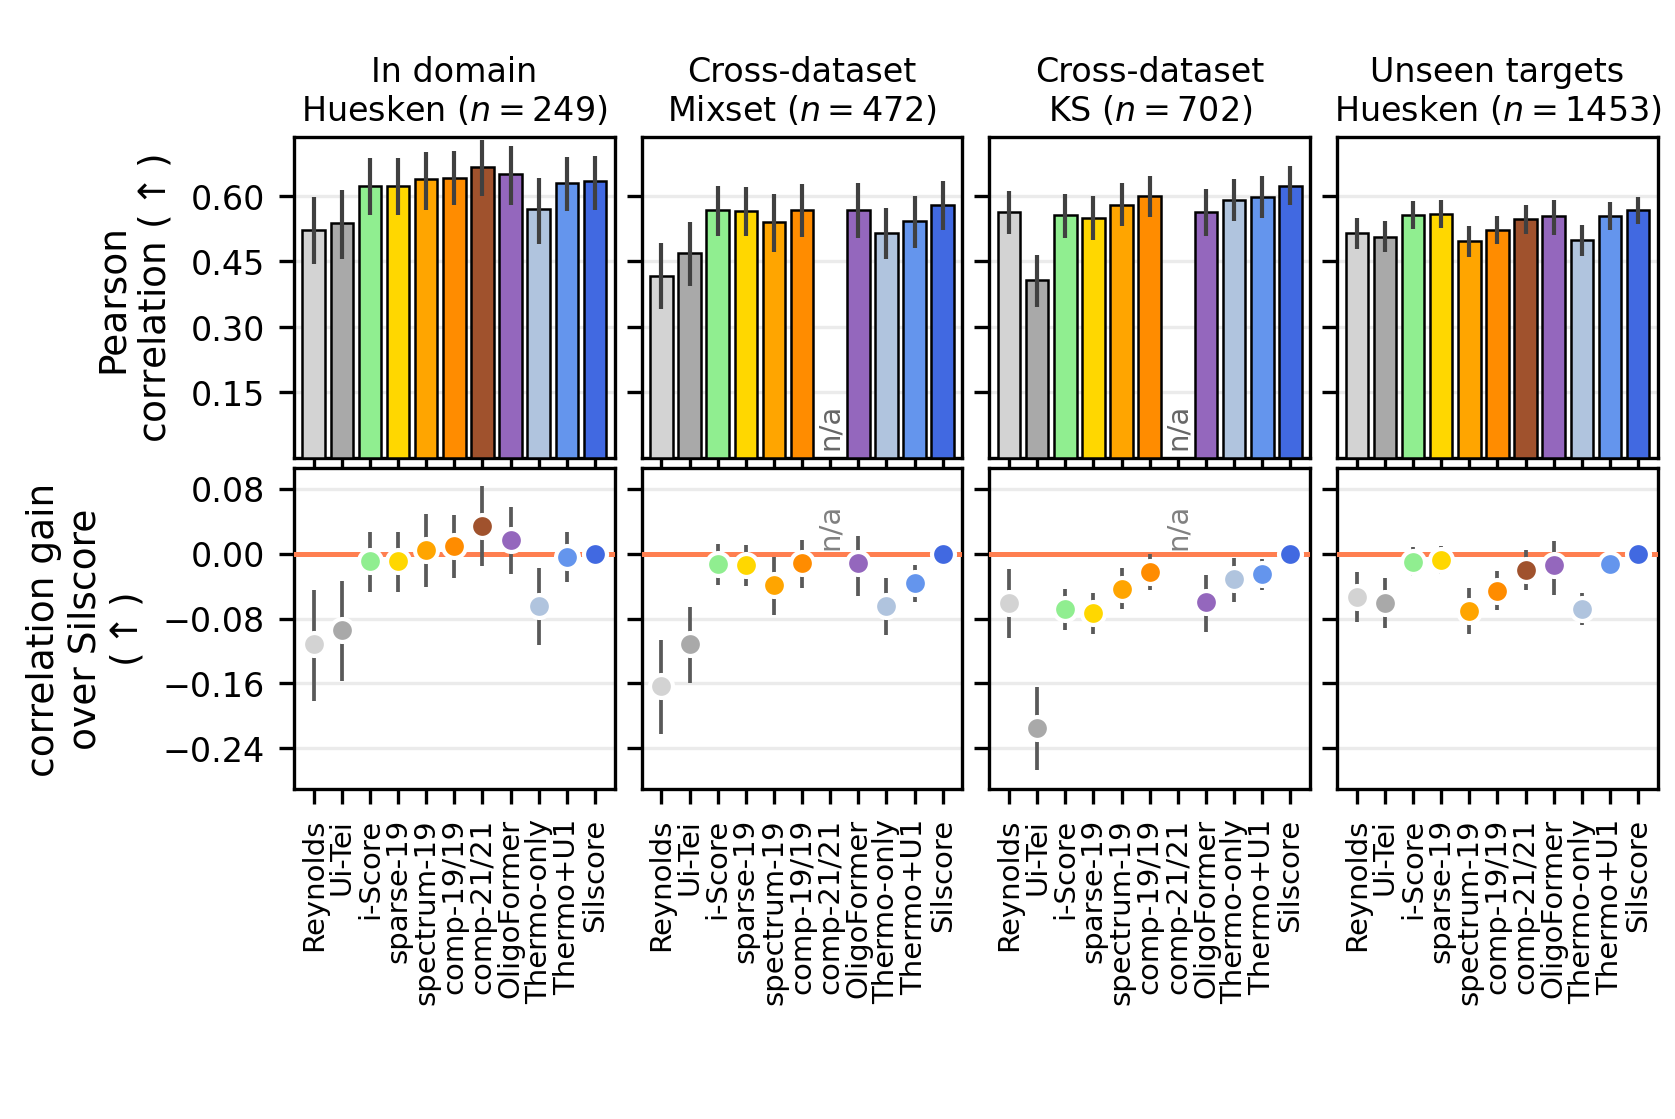

In [2]:
main()
Image(filename=str(ROOT / "output" / "figures" / "fig_performance.png"))